# Grundgerüst Leistungsausweis
Dieses Notebook soll euch als Grundgerüst für euren Leistungsnachweis dienen. Es soll euch eine Idee/ Hilfestellung bieten, wie man einen neuen Datensatz, basierend auf einer Fragestellung, strukturiert analysieren und interpretieren kann. Wie besagt, dient das Notebook als Hilfestellung, ist jedoch keinenfalls vollständig ausgeschöpft. In diesem Sinne dürft ihr auch gerne Sachen miteinbeziehen, welche hier nicht genannt werden. 

-> Bitte schreibt die Antwort zu den jeweiligen Punkten an oberster Stelle unterhalb der Titel (so wie dies auch im Leistungsnachweisbeispiel gemacht wurde).


## Struktur
1. Fragestellung(en) und Datenbeschaffung
2. Daten laden
3. Daten vorbereiten
4. Statistik der Rohdaten (Generell im Longformat)
5. Analyse der Daten

**Wichtig:** Alle graphischen Darstellungen sollten mindestens *Titel, Ticks- und Achsenbeschriftung* beinhalten (Siehe plots im Leistungsnachweisbeispiel)

---

## Gruppenmitglieder
- Leoni Rieser
- Zoé Nitsche 
- Aruni Paramantharajah

## 1. Fragestellung und Datenbeschaffung
### 1.1 Titel: 
Entwicklung der Suizidraten im europäischen Ländervergleich von 2000 bis 2024
### 1.2 Fragestellung:
In welchen der zehn ausgewählten europäischen Länder haben die Suizidraten zwischen 2000 und 2024 am stärksten ab- beziehnungsweise zugenommen und welche möglichen Einflussfaktoren könnten diese Entwicklungen erklären?
### 1.3 Datenquelle(n):
Our World in Data - Suicides
- https://ourworldindata.org/suicide?insight=suicide-rates-have-declined-in-many-countries#key-insights

### 1.4 Daten beschaffen und laden

In [42]:
# Bibliothek laden

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [43]:
# Daten laden
df = pd.read_csv("suicide-rate-who-mdb.csv")
df.head()

,Entity,Code,Year,"Age-standardized death rate from self-inflicted injuries per 100,000 people"
0,Austria,AUT,2000,15.881416
1,Austria,AUT,2001,14.763621
2,Austria,AUT,2002,15.160947
3,Austria,AUT,2003,14.074635
4,Austria,AUT,2004,13.657142


## 2. Daten vorbereiten 

**Welches Format hat mein Datensatz bzw. wie sind meine Kolumnen strukturiert?**

- Der Datensatz liegt im Long-Format vor und besteht aus vier Spalten: Land, Ländercode, Jahr und Suizidrate. Jede Zelle enthält die altersstandardisierte Suizidrate pro 100'000 Einwohner eines bestimmten Landes in einem bestimmten Jahr. Der Untersuchungszeitram erstreckt sich von 2000 bis 2024. Insgesamt werden zehn europäische Länder untersucht.

**Welches Format kann ich für welche Teilschritte verwenden (wann soll ich pivot bzw. wide format verwenden)?**

- Das Long-Format eignet sich für die deskriptive Statistik, die Untersuchung der Datenverteilung sowie die grafische Darstellung der zeitlichen Entwicklung der Suizidraten.
- Das Wide-Format eignet sich insbesondere für den direkten Vergleich der Suizidraten zwischen verschiedenen Jahren und Ländern sowie für die Berechnung absoluter und prozentualer Veränderungen. Mithilfe der Pivot-Funktion wird der Datensatz vom Long-Format ins Wide-Format umgewandelt. Dabei bilden die Länder die Zeilen und die Jahre in Spalten.

**Welche Datentypen kommen in meinem Datensatz vor?**

Im Datensatz kommen drei unterschiedliche Datentypen vor:
- Land: String (str) - Text zur Bezeichnung des Landes.
- Ländercode: String (str) - dreistelliger Buchstabencode zur Identifikation des Landes.
- Jahr: Integer (int64) - Ganzzahl zur Angabe des Erhebungsjahres.
- Suizidrate:: Float (float64) - Dezimalzahl zur Angabe der altersstandardisierten Suizidrate pro 100'000 Einwohner.

**Datenvollständigkeit**

- Der Untersuchungszeitraum erstreckt sich von 2000 bis und mit 2024 und umfasst somit 25 Jahre. Bei zehn untersuchten Ländern wären insgesamt 250 Datenpunkte zu erwarten. Der vorliegende Datensatz enthält jedoch nur 240 Datenpunkte, da für einige Länder die Jahresdaten von 2023 beziehungsweise 2024 fehlen.
Der ursprüngliche Datensatz wird beibehalten. Die fehlenden Jahresdaten werden bei der Analyse und Interpretation der Ergebnisse berücksichtigt.

In [44]:
# Spalten umbenennen
df.columns = ["Land", "Ländercode", "Jahr", "Suizidrate"]

# Informationen zum Datensatz
df.info()

# Anzahl Zeilen und Spalten anzeigen
print(df.shape)

# Datensatz darstellen
display(df.head())

# Datentypen der Spalten überprüfen
display(df.dtypes)

# Anzahl und Namen der Länder
print(df["Land"].nunique())
print(df["Land"].unique())

# Verfügbare Jahre pro Land überprüfen
display(df.groupby("Land")["Jahr"].agg(["min", "max", "nunique"]))

# Anzahl vorhandener Datenpunkte
print(len(df))

# Anzahl Suizidraten mit dem Wert 0
print((df["Suizidrate"] == 0).sum())

# Anzahl fehlender Werte pro Spalte
print(df.isna().sum())

# Umwandlung vom Long-Format ins Wide-Format 
df_wide = df.pivot(index="Land", columns="Jahr", values="Suizidrate")

# Vollständigen Untersuchungszeitraum abbilden 
df_wide = df_wide.reindex(columns=range(2000, 2025))

# Datensatz im Wide-Format darstellen
display(df_wide)

# Fehlende Jahresdaten pro Land überprüfen
print(df_wide.isna().sum(axis=1))


<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Land        240 non-null    str    
 1   Ländercode  240 non-null    str    
 2   Jahr        240 non-null    int64  
 3   Suizidrate  240 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 7.6 KB
(240, 4)


,Land,Ländercode,Jahr,Suizidrate
0,Austria,AUT,2000,15.881416
1,Austria,AUT,2001,14.763621
2,Austria,AUT,2002,15.160947
3,Austria,AUT,2003,14.074635
4,Austria,AUT,2004,13.657142


Land              str
Ländercode        str
Jahr            int64
Suizidrate    float64
dtype: object

10
<StringArray>
[    'Austria',     'Belgium',     'Czechia',      'France',     'Germany',
       'Italy',  'Luxembourg', 'Netherlands',    'Slovenia', 'Switzerland']
Length: 10, dtype: str


,min,max,nunique
Land,,,
Austria,2000,2024,25
Belgium,2000,2022,23
Czechia,2000,2023,24
France,2000,2023,24
Germany,2000,2022,23
Italy,2000,2023,24
Luxembourg,2000,2024,25
Netherlands,2000,2023,24
Slovenia,2000,2023,24


240
0
Land          0
Ländercode    0
Jahr          0
Suizidrate    0
dtype: int64


Jahr,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Land,,,,,,,,,,,,,,,,,,,,,
Austria,15.881416,14.763621,15.160947,14.074635,13.657142,13.110400,11.947490,11.829183,11.175624,11.382416,...,10.238049,9.746500,9.675121,9.439574,8.614792,8.044445,8.218417,9.442171,9.884953,9.794285
Belgium,17.631458,17.608404,16.732760,17.027647,15.953855,15.808666,15.211334,14.247704,15.416194,15.344781,...,13.321423,13.396502,12.308604,12.451210,12.053349,11.945962,11.275168,12.065084,NaN,NaN
Czechia,13.303531,12.967447,12.259133,13.730231,12.579678,12.367986,10.917794,10.713994,10.604980,11.054777,...,10.249176,10.042276,10.676532,10.251711,8.790211,8.885806,9.075679,9.705822,9.333653,NaN
France,14.992606,14.450218,14.594048,14.751859,14.498235,14.091530,13.594213,13.030120,13.221743,13.330879,...,10.644560,9.975401,9.613631,10.207548,10.099815,10.223684,10.144497,10.354827,9.891796,NaN
Germany,10.416157,10.440232,10.304268,10.222207,9.719625,9.211086,8.641727,8.294726,8.354560,8.404640,...,8.526035,8.285569,7.662963,7.725289,7.382837,7.508553,7.291684,7.778309,NaN,NaN
Italy,5.431369,5.298043,5.341181,5.234478,5.090117,4.775917,4.572853,4.634977,4.814739,4.804151,...,4.693946,4.542402,4.691647,4.542666,4.468263,4.321937,4.641532,4.652076,4.616318,NaN
Luxembourg,11.727476,13.618625,15.456644,9.510571,11.241056,8.802053,11.125173,13.573382,6.837666,7.796728,...,9.041553,5.431040,7.209740,6.263736,9.076771,7.588446,4.203250,6.409244,4.576669,6.518391
Netherlands,8.000277,7.799188,8.234311,7.788221,7.801101,8.164005,7.892791,6.931478,7.265642,7.632464,...,8.907627,8.884005,9.096924,8.678001,8.472091,8.483812,8.639382,8.780512,8.479001,NaN
Slovenia,23.934810,23.370281,21.298283,21.998882,20.052595,19.422613,19.814957,15.960115,15.208724,16.234818,...,14.323044,13.296199,13.399402,12.231533,13.122168,11.637178,14.226869,14.440344,11.986767,NaN


Land
Austria        0
Belgium        2
Czechia        1
France         1
Germany        2
Italy          1
Luxembourg     0
Netherlands    1
Slovenia       1
Switzerland    1
dtype: int64


## 3. Statistik der Rohdaten (Analyse im Long-Format)

**Ist meine Variable kontinuierlich oder diskret? Falls diskret, wie viele einzigartige Klassen gibt es? Wieviele Datenpunkte pro Klasse sind vorhanden?**

•	**Land:**
    
    Kategoriale, nominale Variable mit zehn unterschiedlichen Klassen. Jede Klasse entspricht einem untersuchten Land.

•	**Ländercode:**
    
    Kategoriale, nominale Variable mit zehn unterschiedlichen Klassen. Jeder Ländercode dient der eindeutigen Identifikation eines Landes.

•	**Jahr:**
    
    Diskrete, quantitative Variable mit 25 unterschiedlichen Jahreswerten im Zeitraum von 2000 bis 2024.

•	**Suizidrate:**
    
    Kontinuierliche, quantitative Variable mit insgesamt 240 Messwerten. Die altersstandardisierte Suizidrate kann Dezimalwerte annehmen und wird pro 100’000 Einwohner angegeben.

**Anzahl Datenpunkte (Beschreibend und graphische Darstellung)**

Für jede der vier Variablen sind 240 Datenpunkte vorhanden. Bei zehn Ländern und einem Untersuchungszeitraum von 25 Jahren wären insgesamt 250 Datenpunkte zu erwarten. Somit beträgt die Datenvollständigkeit 96 %. Insgesamt fehlen zehn Datenpunkte, was einem Anteil von 4 % entspricht.
Österreich und Luxemburg verfügen über jeweils 25 Datenpunkte. Tschechien, Frankreich, Italien, die Niederlande, Slowenien und die Schweiz verfügen über jeweils 24 Datenpunkte. Belgien und Deutschland verfügen über jeweils 23 Datenpunkte.

**Wo fehlen Datenpunkte?**

Im Untersuchungszeitraum von 2000 bis 2024 fehlen insgesamt zehn Datenpunkte. Von 2000 bis 2022 liegen für alle zehn Länder vollständige Daten vor. Im Jahr 2023 fehlen zwei Datenpunkte (Belgien und Deutschland), im Jahr 2024 acht Datenpunkte.
Die fehlenden Datenpunkte werden nicht durch Nullwerte ersetzt, da dies die statistischen Resultate verfälschen würde. Für einen direkten Vergleich aller zehn Länder eignet sich deshalb insbesondere der Zeitraum von 2000 bis 2022.

**Wie ist die Verteilung der zu untersuchenden Variable(n) (Histogramm, Boxplot, Säulendiagramm)?**

Für die Untersuchung der Verteilungen werden folgende Darstellungsformen verwendet:
•	Land: Säulendiagramm
•	Ländercode: Identische Häufigkeitsverteilung wie bei der Variable Land, weshalb auf eine separate grafische Darstellung verzichtet wird.
•	Jahr: Säulendiagramm
•	Suizidrate: Histogramm und Boxplot

Die kategorialen Variablen Land und Ländercode weisen eine annähernd gleichmässige Häufigkeitsverteilung auf. Bei der Variable Jahr nimmt die Anzahl vorhandener Datenpunkte in den letzten beiden Untersuchungsjahren ab.
Die durchschnittliche Suizidrate aller vorhandenen Messwerte beträgt 10,66 pro 100’000 Einwohner. Der Median liegt bei 10,18 und die Standardabweichung bei 3,71. Der niedrigste Messwert beträgt 4,20 und der höchste 23,93.
Das Histogramm zeigt, dass die Suizidraten besonders häufig im Bereich zwischen ungefähr 7,5 und 10 liegen. Höhere Suizidraten kommen deutlich seltener vor. Die Verteilung ist rechtsschief.
Im allgemeinen Boxplot sind vier obere Ausreisser erkennbar. Diese werden nicht entfernt, da hohe Suizidraten nicht automatisch fehlerhafte Messwerte darstellen.
Der länderspezifische Boxplot zeigt deutliche Unterschiede zwischen den untersuchten Ländern. Slowenien weist den höchsten Median und eine vergleichsweise grosse Streuung auf. Italien weist den niedrigsten Median und eine geringe Streuung auf.

**Vermutest du Zusammenhänge zwischen zwei Variablen (Streuungsdiagramm, Korrelationsmatrix)?**

Wir vermuten einen negativen Zusammenhang zwischen dem Jahr und der Suizidrate. Zur Untersuchung dieses Zusammenhangs werden ein Streuungsdiagramm und eine Korrelationsmatrix erstellt.
Im Streuungsdiagramm ist erkennbar, dass die Suizidraten in mehreren Ländern im Verlauf des Untersuchungszeitraums tendenziell abnehmen. Allerdings unterscheiden sich die zeitlichen Entwicklungen zwischen den einzelnen Ländern.
Der Pearson-Korrelationskoeffizient zwischen dem Jahr und der Suizidrate beträgt rund −0,42. Dies weist auf einen moderaten negativen linearen Zusammenhang hin.
Da Land und Ländercode nominale Variablen sind, eignen sie sich nicht für die Berechnung einer Pearson-Korrelation. Unterschiede zwischen den Ländern werden stattdessen mithilfe der länderspezifischen Boxplots dargestellt.
Die berechnete Korrelation fasst sämtliche vorhandenen Messwerte zusammen und berücksichtigt die Entwicklungen der einzelnen Länder nicht separat. Zudem lässt sich aus einer Korrelation kein ursächlicher Zusammenhang ableiten.


Land           10
Ländercode     10
Jahr           25
Suizidrate    240
dtype: int64

Land
Austria        25
Luxembourg     25
Czechia        24
France         24
Italy          24
Netherlands    24
Slovenia       24
Switzerland    24
Belgium        23
Germany        23
Name: count, dtype: int64

Ländercode
AUT    25
LUX    25
CZE    24
FRA    24
ITA    24
NLD    24
SVN    24
CHE    24
BEL    23
DEU    23
Name: count, dtype: int64

Land          240
Ländercode    240
Jahr          240
Suizidrate    240
dtype: int64

Datenvollständigkeit: 96.0 %


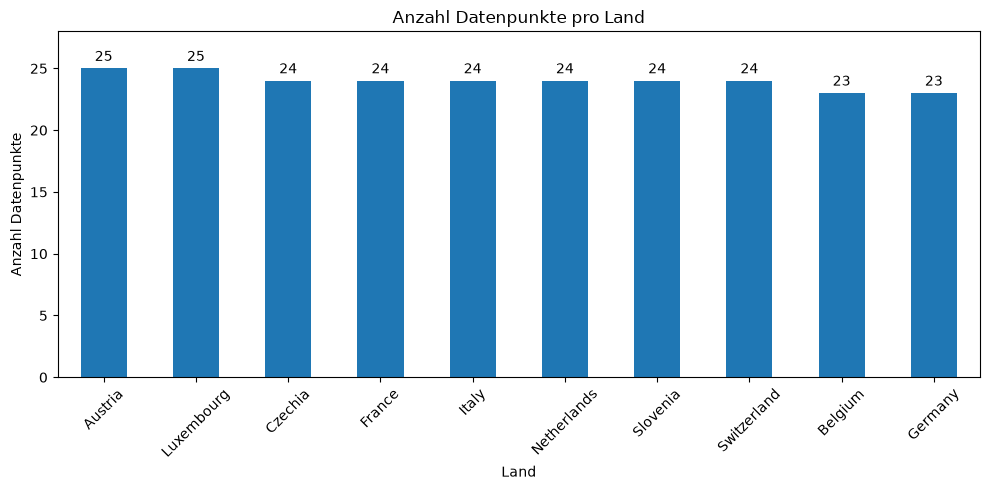

Jahr
2000    10
2001    10
2002    10
2003    10
2004    10
2005    10
2006    10
2007    10
2008    10
2009    10
2010    10
2011    10
2012    10
2013    10
2014    10
2015    10
2016    10
2017    10
2018    10
2019    10
2020    10
2021    10
2022    10
2023     8
2024     2
Name: count, dtype: int64

Jahr
2000    0
2001    0
2002    0
2003    0
2004    0
2005    0
2006    0
2007    0
2008    0
2009    0
2010    0
2011    0
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    2
2024    8
Name: count, dtype: int64

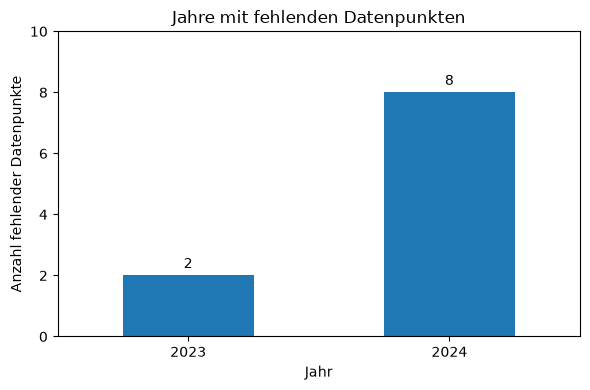

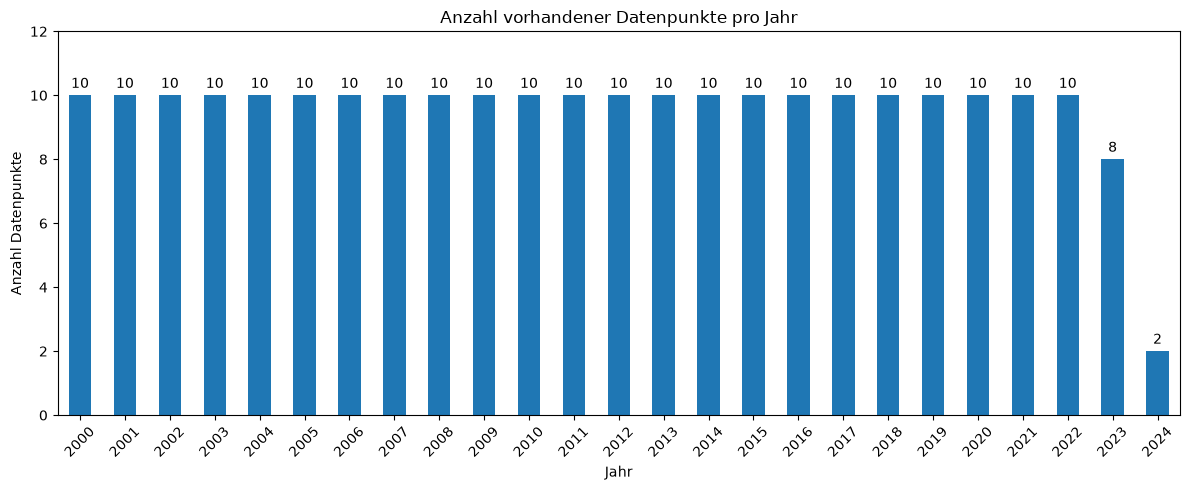

count    240.00
mean      10.66
std        3.71
min        4.20
25%        8.37
50%       10.18
75%       13.23
max       23.93
Name: Suizidrate, dtype: float64

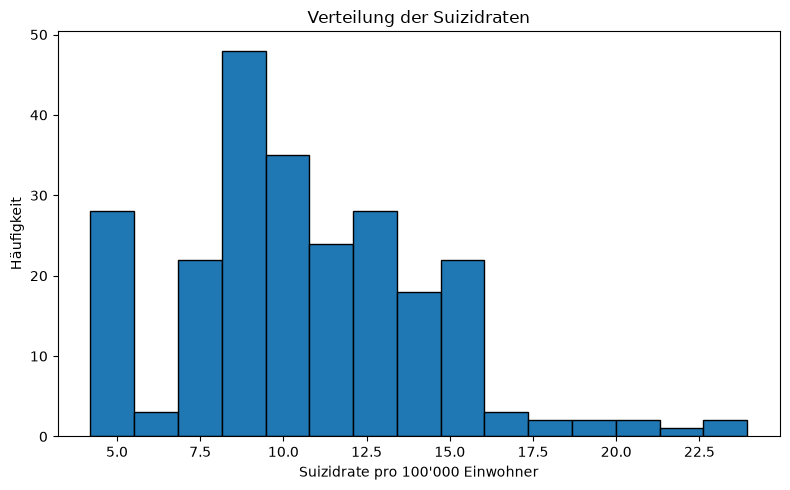

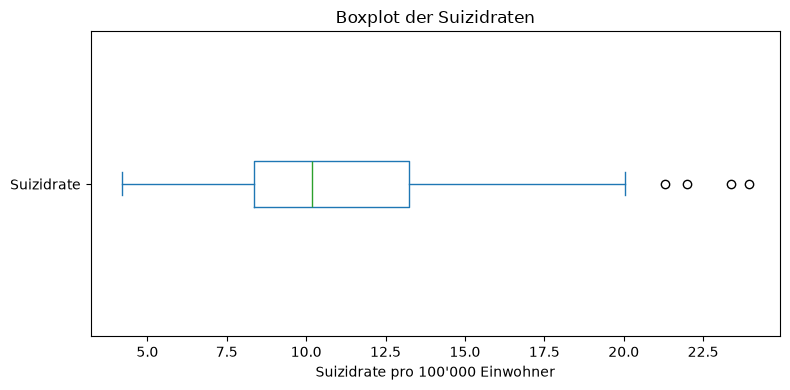

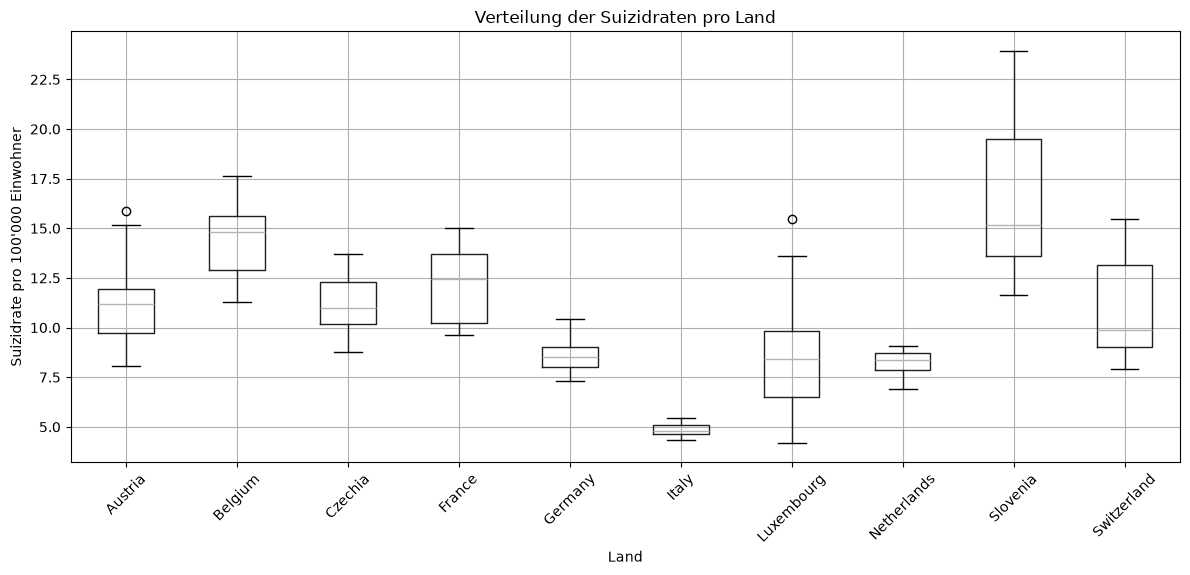

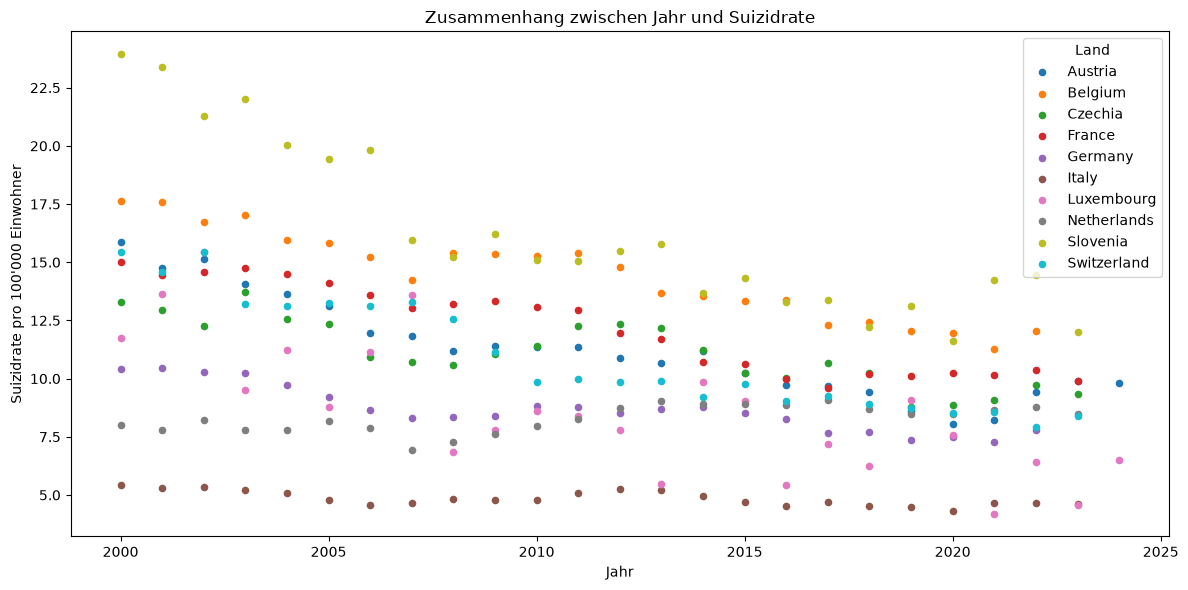

,Jahr,Suizidrate
Jahr,1.00,-0.42
Suizidrate,-0.42,1.00


In [46]:
# Anzahl einzigartiger Werte pro Variable
display(df.nunique())

# Anzahl Datenpunkte pro Land
display(df["Land"].value_counts())

# Anzahl Datenpunkte pro Ländercode
display(df["Ländercode"].value_counts())

# Anzahl vorhandener Datenpunkte pro Variable
display(df.count())

# Datenvollständigkeit in Prozent
erwartete_datenpunkte = df["Land"].nunique() * 25
datenvollständigkeit = len(df) / erwartete_datenpunkte * 100

print("Datenvollständigkeit:", datenvollständigkeit, "%")

# Säulendiagramm: Anzahl Datenpunkte pro Land 
ax = df["Land"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    title="Anzahl Datenpunkte pro Land",
    xlabel="Land",
    ylabel="Anzahl Datenpunkte",
    rot=45,
    ylim=(0, 28)
)

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()


# Anzahl vorhandener Datenpunkte pro Jahr 
daten_pro_jahr = df["Jahr"].value_counts().sort_index()

display(daten_pro_jahr)


# Anzahl fehlender Datenpunkte pro Jahr
fehlende_daten = 10 - daten_pro_jahr

display(fehlende_daten)


# Säulendiagramm: Jahre mit fehlenden Datenpunkten 
ax = fehlende_daten[fehlende_daten > 0].plot(
    kind="bar",
    figsize=(6, 4),
    title="Jahre mit fehlenden Datenpunkten",
    xlabel="Jahr",
    ylabel="Anzahl fehlender Datenpunkte",
    rot=0,
    ylim=(0, 10)
)

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()


# Säulendiagramm: Anzahl vorhandener Datenpunkte pro Jahr 
ax = daten_pro_jahr.plot(
    kind="bar",
    figsize=(12, 5),
    title="Anzahl vorhandener Datenpunkte pro Jahr",
    xlabel="Jahr",
    ylabel="Anzahl Datenpunkte",
    rot=45,
    ylim=(0, 12)
)

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()


# Deskriptive Statistik der Suizidrate
display(df["Suizidrate"].describe().round(2))


# Histogramm: Verteilung der Suizidraten 
df["Suizidrate"].plot(
    kind="hist",
    bins=15,
    figsize=(8, 5),
    edgecolor="black",
    title="Verteilung der Suizidraten",
    xlabel="Suizidrate pro 100'000 Einwohner",
    ylabel="Häufigkeit"
)

plt.tight_layout()
plt.show()


# Boxplot: Verteilung der Suizidraten
df["Suizidrate"].plot(
    kind="box",
    vert=False,
    figsize=(8, 4)
)

plt.title("Boxplot der Suizidraten")
plt.xlabel("Suizidrate pro 100'000 Einwohner")
plt.tight_layout()
plt.show()


# Boxplot: Verteilung der Suizidraten pro Land 
df.boxplot(
    column="Suizidrate",
    by="Land",
    figsize=(12, 6)
)

plt.suptitle("")
plt.title("Verteilung der Suizidraten pro Land")
plt.xlabel("Land")
plt.ylabel("Suizidrate pro 100'000 Einwohner")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Streuungsdiagramm: Zusammenhang zwischen Jahr und Suizidrate 
fig, ax = plt.subplots(figsize=(12, 6))

farben = plt.get_cmap("tab10")

for i, land in enumerate(df["Land"].unique()):
    df[df["Land"] == land].plot(
        kind="scatter",
        x="Jahr",
        y="Suizidrate",
        ax=ax,
        label=land,
        color=farben(i)
    )

plt.title("Zusammenhang zwischen Jahr und Suizidrate")
plt.xlabel("Jahr")
plt.ylabel("Suizidrate pro 100'000 Einwohner")
plt.legend(title="Land")
plt.tight_layout()
plt.show()

# Korrelationsmatrix berechnen
korrelation = df[["Jahr", "Suizidrate"]].corr()

# Korrelationsmatrix farblich darstellen 
display(korrelation.style.background_gradient(
    cmap="coolwarm",
    vmin=-1,
    vmax=1
).format("{:.2f}"))



## 4. Analyse 

### Vorgehen
- Spezifische Untersuchung der Fragestellung (Berechnungen)
- Visualisieren der Resultate: Verwendet Achsenbeschriftung und überlegt euch, welche Art von Darstellung sinnvoll ist (Kuchen-, Säulen, Liniendiagramm; 2 y-Achsen?)
- Beschreiben der Beobachtungen
- Interpretation der Resultate (Hypothesen zu den Resultaten)
- Untermauern der Interpretation mittels Hinweise zur Literatur (Mögliche Zusammenhänge aufzeigen).

